## EDA: Tương quan AQI & Thời tiết — 11 thành phố Việt Nam

# **Mục tiêu:** Phân tích mối quan hệ giữa ô nhiễm không khí (PM2.5, AQI)
# và các yếu tố thời tiết (nhiệt độ, độ ẩm, gió).

# **Câu hỏi cần trả lời:**
# 1. PM2.5 có tương quan với nhiệt độ / độ ẩm / gió không?
# 2. Thời điểm nào trong ngày ô nhiễm nhất?
# 3. Thành phố nào ô nhiễm nhất?
# 4. Có pattern "temperature inversion" buổi sáng sớm không?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import psycopg2
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)


conn = psycopg2.connect(
    host="localhost",
    port="5433",
    dbname="weather_aqi",
    user="datauser",
    password="datapass",
)

print("✅ Connected to database")


✅ Connected to database


In [3]:
# %%
# Load toàn bộ processed data
df = pd.read_sql("""
    SELECT city_code, timestamp_local, 
           temperature_c, humidity_pct, windspeed_kmh,
           pm2_5, pm10, aqi_eu, health_risk
    FROM processed.hourly_metrics
    ORDER BY city_code, timestamp_local
""", conn)

# Parse datetime
df["timestamp_local"] = pd.to_datetime(df["timestamp_local"])
df["hour"] = df["timestamp_local"].dt.hour
df["day_of_week"] = df["timestamp_local"].dt.day_name()
df["date"] = df["timestamp_local"].dt.date

print(f"Total rows: {len(df):,}")
print(f"Date range: {df['timestamp_local'].min()} → {df['timestamp_local'].max()}")
print(f"Cities: {df['city_code'].nunique()}")
print(f"\n--- Missing values ---")
print(df.isnull().sum())


Total rows: 1,584
Date range: 2026-05-23 17:00:00+00:00 → 2026-05-29 16:00:00+00:00
Cities: 11

--- Missing values ---
city_code          0
timestamp_local    0
temperature_c      0
humidity_pct       0
windspeed_kmh      0
pm2_5              0
pm10               0
aqi_eu             0
health_risk        0
hour               0
day_of_week        0
date               0
dtype: int64


In [5]:
summary = (
    df.groupby("city_code")
    .agg(
        avg_pm25=("pm2_5", "mean"),
        max_pm25=("pm2_5", "max"),
        avg_aqi=("aqi_eu", "mean"),
        max_aqi=("aqi_eu", "max"),
        avg_temp=("temperature_c", "mean"),
        avg_humidity=("humidity_pct", "mean"),
        avg_wind=("windspeed_kmh", "mean"),
        data_points=("pm2_5", "count"),
    )
    .round(1)
    .sort_values("avg_pm25", ascending=False)
)

print("Thống kê theo thành phố (sắp xếp theo PM2.5 trung bình):\n")
display(summary)


Thống kê theo thành phố (sắp xếp theo PM2.5 trung bình):



,avg_pm25,max_pm25,avg_aqi,max_aqi,avg_temp,avg_humidity,avg_wind,data_points
city_code,,,,,,,,
HCM,42.5,80.6,73.3,79,29.3,78.8,5.6,144
HN,35.5,68.0,69.4,85,31.0,75.0,10.4,144
DN,34.6,65.2,72.4,98,31.9,67.5,8.3,144
CT,31.0,119.7,62.7,94,28.3,83.0,8.7,144
VINH,26.6,66.1,57.6,70,31.8,71.2,7.4,144
QN,26.3,39.2,61.4,77,30.6,72.4,11.9,144
NT,26.3,49.1,59.8,72,30.9,68.8,7.4,144
HUE,25.8,41.4,60.9,79,31.8,65.8,8.5,144
VT,18.5,38.5,39.1,65,29.6,75.8,12.8,144


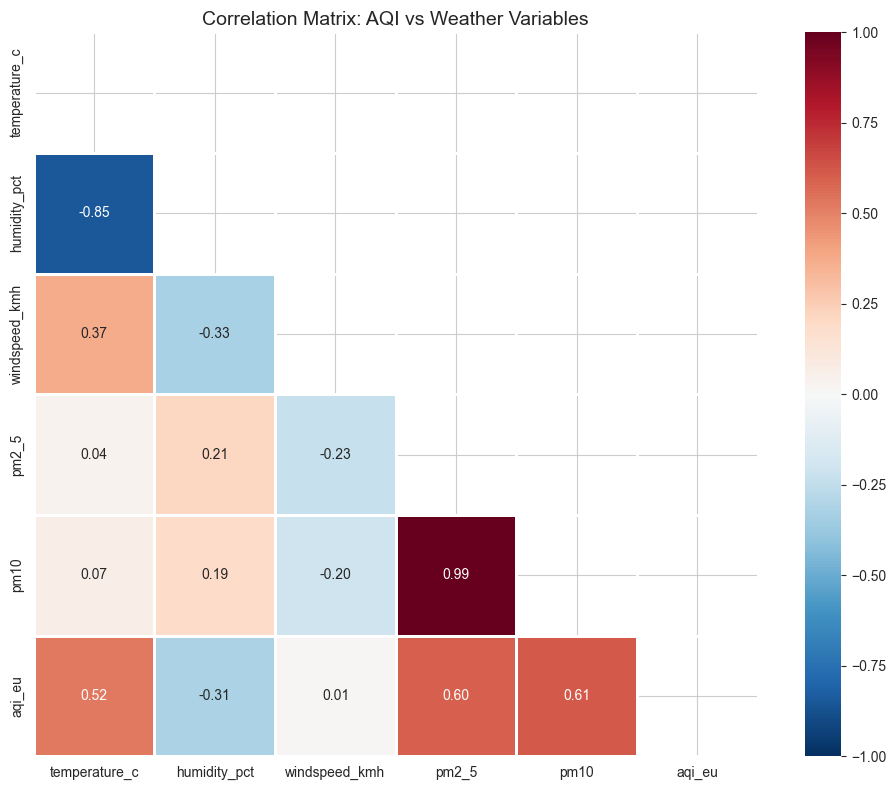


 Key findings:
   PM2.5 vs Wind Speed: r = -0.231
   PM2.5 vs Temperature: r = 0.037
   PM2.5 vs Humidity: r = 0.213


In [6]:
numeric_cols = ["temperature_c", "humidity_pct", "windspeed_kmh", "pm2_5", "pm10", "aqi_eu"]
corr_matrix = df[numeric_cols].corr()

# Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # chỉ show nửa dưới
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    ax=ax,
)
ax.set_title("Correlation Matrix: AQI vs Weather Variables", fontsize=14)
plt.tight_layout()
plt.savefig("../docs/screenshots/correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n Key findings:")
print(f"   PM2.5 vs Wind Speed: r = {corr_matrix.loc['pm2_5', 'windspeed_kmh']:.3f}")
print(f"   PM2.5 vs Temperature: r = {corr_matrix.loc['pm2_5', 'temperature_c']:.3f}")
print(f"   PM2.5 vs Humidity: r = {corr_matrix.loc['pm2_5', 'humidity_pct']:.3f}")
